In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("my_file (1).csv")

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (20, 11)


,Rank,Peak,All Time Peak,Actual gross,Adjusted gross (in 2022 dollars),Artist,Tour title,Year(s),Shows,Average gross,Ref.
0,1,1,2,"$780,000,000","$780,000,000",Taylor Swift,The Eras Tour †,2023–2024,56,"$13,928,571",[1]
1,2,1,7[2],"$579,800,000","$579,800,000",Beyoncé,Renaissance World Tour,2023,56,"$10,353,571",[3]
2,3,1[4],2[5],"$411,000,000","$560,622,615",Madonna,Sticky & Sweet Tour ‡[4][a],2008–2009,85,"$4,835,294",[6]
3,4,2[7],10[7],"$397,300,000","$454,751,555",Pink,Beautiful Trauma World Tour,2018–2019,156,"$2,546,795",[7]
4,5,2[4],NaN,"$345,675,146","$402,844,849",Taylor Swift,Reputation Stadium Tour,2018,53,"$6,522,173",[8]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   Rank                              20 non-null     int64 
 1   Peak                              9 non-null      object
 2   All Time Peak                     6 non-null      object
 3   Actual gross                      20 non-null     object
 4   Adjusted gross (in 2022 dollars)  20 non-null     object
 5   Artist                            20 non-null     object
 6   Tour title                        20 non-null     object
 7   Year(s)                           20 non-null     object
 8   Shows                             20 non-null     int64 
 9   Average gross                     20 non-null     object
 10  Ref.                              20 non-null     object
dtypes: int64(2), object(9)
memory usage: 1.8+ KB


In [2]:
# Missing values (count and percentage)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"missing": missing, "percent": missing_pct}).sort_values("percent", ascending=False))

# Duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Quick stats
display(df.describe(include="all").T)

                                  missing  percent
All Time Peak                          14     70.0
Peak                                   11     55.0
Rank                                    0      0.0
Actual gross                            0      0.0
Adjusted gross (in 2022 dollars)        0      0.0
Artist                                  0      0.0
Tour title                              0      0.0
Year(s)                                 0      0.0
Shows                                   0      0.0
Average gross                           0      0.0
Ref.                                    0      0.0

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Rank,20.0,NaN,NaN,NaN,10.45,5.942488,1.0,5.75,10.5,15.25,20.0
Peak,9,7,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
All Time Peak,6,6,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Actual gross,20,20,"$780,000,000",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Adjusted gross (in 2022 dollars),20,20,"$780,000,000",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Artist,20,9,Taylor Swift,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tour title,20,20,The Eras Tour †,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year(s),20,16,2013–2014,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shows,20.0,NaN,NaN,NaN,110.0,66.507617,41.0,59.0,87.0,134.5,325.0
Average gross,20,20,"$13,928,571",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
import re

df_clean = df.copy()

# 1) Standardize column names
df_clean.columns = (df_clean.columns.str.strip().str.lower()
                    .str.replace(r"\(.*?\)", "", regex=True)
                    .str.replace(r"[^a-z0-9]+", "_", regex=True)
                    .str.strip("_"))

# 2) Drop the reference column (not useful for analysis)
df_clean = df_clean.drop(columns=["ref"], errors="ignore")

# 3) Remove footnote markers like [1], [a], †, ‡
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = (df_clean[col].astype(str)
                     .str.replace(r"\[.*?\]", "", regex=True)
                     .str.replace(r"[†‡*]", "", regex=True)
                     .str.strip()
                     .replace("nan", np.nan))

# 4) Convert money columns to numbers
for col in ["actual_gross", "adjusted_gross", "average_gross"]:
    df_clean[col] = pd.to_numeric(df_clean[col].str.replace(r"[$,]", "", regex=True), errors="coerce")

# 5) Convert numeric columns
for col in ["rank", "peak", "all_time_peak", "shows"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# 6) Split the year range into start and end year
years = df_clean["year"].str.replace("–", "-", regex=False).str.split("-", expand=True)
df_clean["start_year"] = pd.to_numeric(years[0], errors="coerce")
df_clean["end_year"] = pd.to_numeric(years[1].fillna(years[0]), errors="coerce")
df_clean = df_clean.drop(columns=["year"])

# 7) Validation: does average gross match actual gross / shows?
df_clean["avg_check"] = (df_clean["actual_gross"] / df_clean["shows"]).round(0)

# 8) Final checks
df_clean.info()
print("Missing values:\n", df_clean.isnull().sum())
print("Duplicates:", df_clean.duplicated().sum())
display(df_clean.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   rank            20 non-null     int64  
 1   peak            9 non-null      float64
 2   all_time_peak   6 non-null      float64
 3   actual_gross    20 non-null     int64  
 4   adjusted_gross  20 non-null     int64  
 5   artist          20 non-null     object 
 6   tour_title      20 non-null     object 
 7   shows           20 non-null     int64  
 8   average_gross   20 non-null     int64  
 9   start_year      20 non-null     int64  
 10  end_year        20 non-null     int64  
 11  avg_check       20 non-null     float64
dtypes: float64(3), int64(7), object(2)
memory usage: 2.0+ KB
Missing values:
 rank               0
peak              11
all_time_peak     14
actual_gross       0
adjusted_gross     0
artist             0
tour_title         0
shows              0
average_gross      0

,rank,peak,all_time_peak,actual_gross,adjusted_gross,artist,tour_title,shows,average_gross,start_year,end_year,avg_check
0,1,1.0,2.0,780000000,780000000,Taylor Swift,The Eras Tour,56,13928571,2023,2024,13928571.0
1,2,1.0,7.0,579800000,579800000,Beyoncé,Renaissance World Tour,56,10353571,2023,2023,10353571.0
2,3,1.0,2.0,411000000,560622615,Madonna,Sticky & Sweet Tour,85,4835294,2008,2009,4835294.0
3,4,2.0,10.0,397300000,454751555,Pink,Beautiful Trauma World Tour,156,2546795,2018,2019,2546795.0
4,5,2.0,NaN,345675146,402844849,Taylor Swift,Reputation Stadium Tour,53,6522173,2018,2018,6522173.0


### Handling missing values
`Peak` (55%) and `All Time Peak` (70%) have many missing values. Imputing them would
create fake data, so I kept them as NaN, added flag columns, and excluded them from the main analysis.

In [4]:
# Keep missing values as NaN (they are not errors), and add a flag column
df_clean["has_peak_data"] = df_clean["peak"].notna()
df_clean["has_all_time_peak_data"] = df_clean["all_time_peak"].notna()

# These two columns are >50% empty, so exclude them from the main analysis
analysis_df = df_clean.drop(columns=["peak", "all_time_peak"])

In [5]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   rank                    20 non-null     int64  
 1   peak                    9 non-null      float64
 2   all_time_peak           6 non-null      float64
 3   actual_gross            20 non-null     int64  
 4   adjusted_gross          20 non-null     int64  
 5   artist                  20 non-null     object 
 6   tour_title              20 non-null     object 
 7   shows                   20 non-null     int64  
 8   average_gross           20 non-null     int64  
 9   start_year              20 non-null     int64  
 10  end_year                20 non-null     int64  
 11  avg_check               20 non-null     float64
 12  has_peak_data           20 non-null     bool   
 13  has_all_time_peak_data  20 non-null     bool   
dtypes: bool(2), float64(3), int64(7), object(2)


In [6]:
# Does average_gross match actual_gross / shows?
df_clean["avg_diff_pct"] = ((df_clean["avg_check"] - df_clean["average_gross"]).abs()
                            / df_clean["average_gross"] * 100).round(2)
display(df_clean[["artist", "average_gross", "avg_check", "avg_diff_pct"]])
print("Max difference (%):", df_clean["avg_diff_pct"].max())

# Sanity checks
print("Adjusted < Actual rows:", (df_clean["adjusted_gross"] < df_clean["actual_gross"]).sum())
print("Start year > end year:", (df_clean["start_year"] > df_clean["end_year"]).sum())

,artist,average_gross,avg_check,avg_diff_pct
0,Taylor Swift,13928571,13928571.0,0.00
1,Beyoncé,10353571,10353571.0,0.00
2,Madonna,4835294,4835294.0,0.00
3,Pink,2546795,2546795.0,0.00
4,Taylor Swift,6522173,6522173.0,0.00
5,Madonna,3467709,3467709.0,0.00
6,Celine Dion,2137405,2137405.0,0.00
7,Pink,6282927,6282927.0,0.00
8,Beyoncé,5226215,5226215.0,0.00
9,Taylor Swift,2945882,2945882.0,0.00


Max difference (%): 0.18
Adjusted < Actual rows: 0
Start year > end year: 0


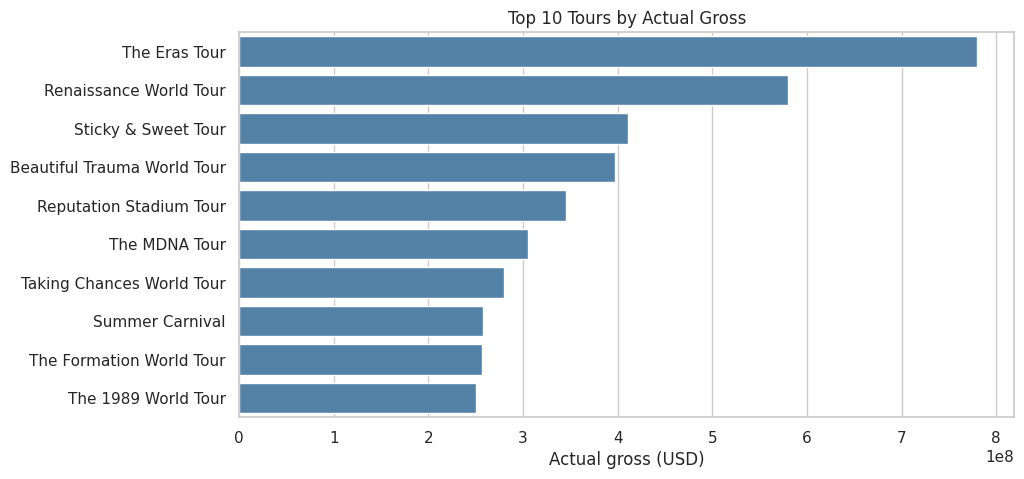

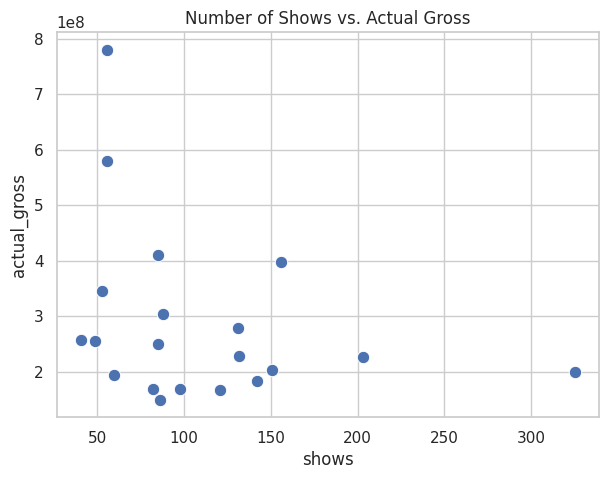

Correlation (shows vs gross): -0.31


,artist,tour_title,actual_gross,adjusted_gross,inflation_uplift_pct
13,Cher,Living Proof: The Farewell Tour,200000000,299676265,49.8
14,Madonna,Confessions Tour,194000000,281617035,45.2
2,Madonna,Sticky & Sweet Tour,411000000,560622615,36.4
6,Celine Dion,Taking Chances World Tour,280000000,381932682,36.4
11,Lady Gaga,The Monster Ball Tour,227400000,295301479,29.9
5,Madonna,The MDNA Tour,305158363,388978496,27.5
16,Lady Gaga,Born This Way Ball,170000000,213568571,25.6
15,Pink,The Truth About Love Tour,184000000,227452347,23.6
19,Taylor Swift,The Red Tour,150000000,185423109,23.6
10,Beyoncé,The Mrs. Carter Show World Tour,229100000,283202896,23.6


decade
2000s     5
2010s    12
2020s     3
Name: count, dtype: int64


In [7]:
sns.set_theme(style="whitegrid")

# 1) Top 10 tours by actual gross
top10 = df_clean.nlargest(10, "actual_gross")
plt.figure(figsize=(10, 5))
sns.barplot(data=top10, y="tour_title", x="actual_gross", color="steelblue")
plt.title("Top 10 Tours by Actual Gross")
plt.xlabel("Actual gross (USD)")
plt.ylabel("")
plt.show()

# 2) Shows vs. gross
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="shows", y="actual_gross", s=80)
plt.title("Number of Shows vs. Actual Gross")
plt.show()
print("Correlation (shows vs gross):", df_clean["shows"].corr(df_clean["actual_gross"]).round(2))

# 3) Inflation effect
df_clean["inflation_uplift_pct"] = ((df_clean["adjusted_gross"] - df_clean["actual_gross"])
                                    / df_clean["actual_gross"] * 100).round(1)
display(df_clean[["artist", "tour_title", "actual_gross", "adjusted_gross", "inflation_uplift_pct"]]
        .sort_values("inflation_uplift_pct", ascending=False).head(10))

# 4) Gross per show (efficiency) and tours per decade
df_clean["decade"] = (df_clean["start_year"] // 10 * 10).astype(str) + "s"
print(df_clean["decade"].value_counts().sort_index())

# 📊 Insights – Highest-Grossing Concert Tours

## 1) Data Quality
- **20 tours** and **9 artists**, no duplicate rows.
- `Peak` (55% missing) and `All Time Peak` (70% missing) were excluded from the analysis instead of being filled with made-up values.
- Average gross per show matches (actual gross ÷ number of shows) in 19 of 20 tours. The maximum difference is only **0.18%** (The Monster Ball – Lady Gaga), which is a rounding difference.
- No tour has an adjusted gross lower than its actual gross, and no tour has a start year later than its end year.

## 2) Top-Grossing Tours
| Rank | Tour | Artist | Actual Gross |
|---|---|---|---|
| 1 | The Eras Tour | Taylor Swift | $780M |
| 2 | Renaissance World Tour | Beyoncé | $579.8M |
| 3 | Sticky & Sweet Tour | Madonna | $411M |
| 4 | Beautiful Trauma World Tour | Pink | $397.3M |

- The gap between #1 and #2 is about **$200M** (the top tour earned roughly 35% more).

## 3) Artist Distribution
- **Taylor Swift** and **Madonna**: 4 tours each (20% of the list each).
- **Pink** and **Beyoncé**: 3 tours each.
- **Lady Gaga**: 2 tours. The remaining artists (Celine Dion, Katy Perry, Cher, Adele): 1 tour each.

## 4) Revenue Does Not Depend on the Number of Shows
- Correlation between number of shows and gross = **-0.31** (weak negative).
- Eras and Renaissance (**56 shows** each) out-earned Beautiful Trauma (**156 shows**).
- Average number of shows in the list is **110** (median 87, max 325).
- The sample is small (20 rows), so the correlation is only a preliminary indicator.

## 5) Per-Show Efficiency
| Tour | Average Gross per Show |
|---|---|
| The Eras Tour | $13.93M |
| Renaissance | $10.35M |
| Reputation | $6.52M |
| Sticky & Sweet | $4.84M |
| Beautiful Trauma | $2.55M |

- A single Eras show earned about **5.5x** a Beautiful Trauma show.
- Pink earned $397M vs. Madonna's $411M, but with almost **double the number of shows** (156 vs. 85).

## 6) Inflation Effect (2022 dollars)
| Tour | Actual | Adjusted | Uplift |
|---|---|---|---|
| Cher – Farewell Tour | $200M | $299.7M | **+49.8%** |
| Madonna – Confessions | $194M | $281.6M | +45.2% |
| Madonna – Sticky & Sweet | $411M | $560.6M | +36.4% |
| Celine Dion – Taking Chances | $280M | $381.9M | +36.4% |

- After adjustment, Sticky & Sweet ($560.6M) comes very close to Renaissance ($579.8M).
- Eras and Renaissance show no uplift because they are recent (2022–2023).

## 7) Time Distribution
- **2000s:** 5 tours | **2010s:** 12 tours (60%) | **2020s:** 3 tours.
- Most record-setting tours are recent, reflecting the growth of the live-music industry and rising ticket prices.

##  Methodological Notes
- The list contains **only top-grossing tours** (survivorship bias), so it does not represent all artists.
- Eras (†) and Sticky & Sweet (‡) carry footnotes in the source and should be reviewed before final use.